Dataset Shape: (10000, 6)

CBOW Model Trained Successfully!

Selected Word: hard
Word Embedding: [-1.83859527e-01  1.29114866e-01  1.07651062e-01  9.76561829e-02
  3.30061801e-02 -1.77385628e-01 -9.44019705e-02  3.50758493e-01
 -1.44342529e-02  2.19252724e-02 -2.24836498e-01 -8.93189833e-02
  3.37907150e-02  3.03521249e-02  1.58110559e-02 -6.16154410e-02
  1.38411438e-02 -9.93530825e-02  1.75771601e-02 -1.97007582e-01
  9.78537053e-02  1.16532341e-01  1.54549647e-02 -3.89286643e-03
 -8.14785901e-03  3.51299793e-02 -1.03039667e-01 -1.02199323e-01
  3.65276379e-03  3.78886529e-04  1.49472862e-01  9.02573168e-02
 -6.57030419e-02  1.24484330e-01 -6.82408363e-02  6.22665770e-02
 -4.10645604e-02 -2.52875924e-01 -1.85592070e-01 -2.17846811e-01
 -4.76163998e-02  4.58617142e-05 -3.31035443e-02 -7.51969591e-02
 -4.34558801e-02 -5.67238256e-02 -1.29288301e-01  2.10173652e-02
  1.29452080e-01  9.35787261e-02  4.14585471e-02 -9.64629427e-02
 -9.96557400e-02  5.85636534e-02 -2.16563389e-01  2.763691

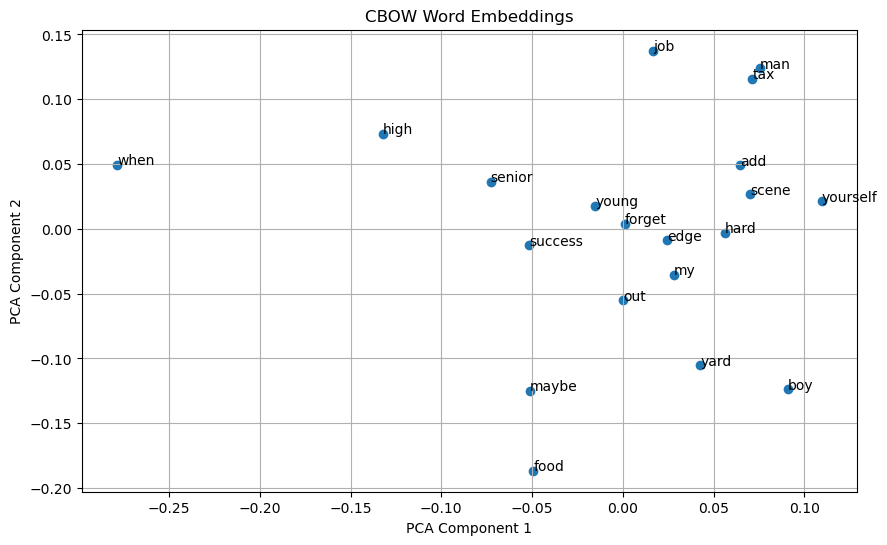

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.decomposition import PCA

# Step 1: Load Dataset
df = pd.read_csv("twitter_dataset.csv")

print("Dataset Shape:", df.shape)

# Step 2: Clean and Tokenize Tweets
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+|#", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    return text.split()

tweets = df["Text"].dropna().apply(clean_text).tolist()

# Step 3: Train CBOW Model
model = Word2Vec(
    sentences=tweets,
    vector_size=100,
    window=5,
    min_count=1,
    sg=0,
    workers=4,
    epochs=10
)

print("\nCBOW Model Trained Successfully!")

# Step 4: Display Word Embedding
word = model.wv.index_to_key[0]

print("\nSelected Word:", word)
print("Word Embedding:", model.wv[word])

# Step 5: Find Similar Words
print("\nSimilar Words:")
print(model.wv.most_similar(word, topn=5))

# Step 6: Plot Word Embeddings
words = model.wv.index_to_key[:20]

vectors = [model.wv[w] for w in words]

pca = PCA(n_components=2)
result = pca.fit_transform(vectors)

plt.figure(figsize=(10, 6))

plt.scatter(result[:, 0], result[:, 1])

for i, word in enumerate(words):
    plt.annotate(word, (result[i, 0], result[i, 1]))

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("CBOW Word Embeddings")
plt.grid(True)
plt.show()